# EDA Awal Data Fenotipik ABIDE I

Notebook ini hanya digunakan untuk **inspeksi dan eksplorasi awal** file fenotipik ABIDE I. Tidak ada baris atau kolom yang dihapus, tidak ada imputasi untuk pemodelan, dan tidak ada matching dengan citra sMRI.

Nilai khusus seperti `-9999` dilaporkan sebagai *missing secara konseptual* pada salinan analisis saja. Maknanya tetap perlu dikonfirmasi melalui dokumentasi ABIDE I untuk setiap variabel.

In [27]:
# Instalasi tidak diperlukan jika notebook dijalankan pada Colab/Jupyter standar.
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Konfigurasi path

Ubah hanya `CSV_PATH` bila lokasi file berbeda. Path relatif berikut cocok jika notebook berada di folder `notebook/` dan folder `dataset/` berada satu tingkat di atasnya. Di Google Colab, path dapat diganti menjadi lokasi setelah Google Drive di-*mount*. Semua tabel dan grafik hanya ditampilkan di output cell notebook; tidak ada file hasil yang disimpan ke folder lain.

In [28]:
CSV_PATH = Path("../dataset/fenotipik/Phenotypic_V1_0b.csv")

print(f"File CSV : {CSV_PATH.resolve()}")
if not CSV_PATH.is_file():
    raise FileNotFoundError(
        f"File tidak ditemukan: {CSV_PATH.resolve()}. "
        "Silakan ubah CSV_PATH pada sel konfigurasi."
    )

File CSV : C:\Users\Lenovo\OneDrive\Documents\TUGAS AKHIR\dataset\fenotipik\Phenotypic_V1_0b.csv


## 2. Fungsi bantu

Fungsi berikut hanya membantu pelaporan, penyimpanan tabel, dan pembuatan grafik. Tidak ada fungsi yang mengubah `df_raw`.

In [29]:
SPECIAL_MISSING_VALUES = {-9999, -9999.0, "-9999", "-9999.0"}
PREFERRED_COLUMNS = [
    "DX_GROUP", "AGE_AT_SCAN", "SEX", "FIQ", "HANDEDNESS_CATEGORY",
    "SITE_ID", "AGE_AT_MPRAGE", "BMI", "VIQ", "PIQ",
]
CATEGORICAL_CANDIDATES = [
    "DX_GROUP", "SEX", "HANDEDNESS_CATEGORY", "SITE_ID",
    "FIQ_TEST_TYPE", "VIQ_TEST_TYPE", "PIQ_TEST_TYPE",
    "EYE_STATUS_AT_SCAN", "COMORBIDITY", "CURRENT_MED_STATUS",
]
NUMERIC_CANDIDATES = [
    "AGE_AT_SCAN", "FIQ", "VIQ", "PIQ", "AGE_AT_MPRAGE", "BMI",
    "ADI_R_SOCIAL_TOTAL_A", "ADI_R_VERBAL_TOTAL_BV", "ADI_R_RRB_TOTAL_C",
    "ADOS_TOTAL", "SRS_RAW_TOTAL", "SCQ_TOTAL", "AQ_TOTAL",
]

def existing(columns, frame):
    return [column for column in columns if column in frame.columns]

def finish_figure():
    """Menampilkan grafik di notebook tanpa menyimpan file."""
    plt.tight_layout()

def conceptual_missing_mask(series):
    return series.isna() | series.isin(SPECIAL_MISSING_VALUES)

def analysis_copy(frame):
    """Salinan untuk grafik/statistik; df_raw tidak disentuh."""
    copied = frame.copy()
    for column in copied.columns:
        copied[column] = copied[column].replace(list(SPECIAL_MISSING_VALUES), np.nan)
    return copied

def report_unavailable(columns, frame):
    unavailable = [column for column in columns if column not in frame.columns]
    if unavailable:
        print("Kolom tidak tersedia, analisis dilewati:", ", ".join(unavailable))
    return unavailable

## 3. Memuat dan menginspeksi struktur data

Pembacaan mencoba UTF-8 terlebih dahulu lalu beberapa encoding umum. Data asli disimpan pada `df_raw` dan tidak diubah sepanjang notebook.

In [30]:
encodings_to_try = ["utf-8", "utf-8-sig", "latin-1"]
df_raw = None
read_errors = []
for encoding in encodings_to_try:
    try:
        df_raw = pd.read_csv(CSV_PATH, encoding=encoding, low_memory=False)
        print(f"CSV berhasil dibaca dengan encoding: {encoding}")
        break
    except UnicodeDecodeError as error:
        read_errors.append(f"{encoding}: {error}")

if df_raw is None:
    raise UnicodeDecodeError(
        "unknown", b"", 0, 1,
        "Tidak dapat membaca CSV dengan encoding yang dicoba: " + "; ".join(read_errors)
    )

df_raw.head()

CSV berhasil dibaca dengan encoding: utf-8


,SITE_ID,SUB_ID,FILE_ID,DX_GROUP,DSM_IV_TR,AGE_AT_SCAN,SEX,HANDEDNESS_CATEGORY,HANDEDNESS_SCORES,FIQ,VIQ,PIQ,FIQ_TEST_TYPE,VIQ_TEST_TYPE,PIQ_TEST_TYPE,ADI_R_SOCIAL_TOTAL_A,ADI_R_VERBAL_TOTAL_BV,ADI_RRB_TOTAL_C,ADI_R_ONSET_TOTAL_D,ADI_R_RSRCH_RELIABLE,ADOS_MODULE,ADOS_TOTAL,ADOS_COMM,ADOS_SOCIAL,ADOS_STEREO_BEHAV,ADOS_RSRCH_RELIABLE,ADOS_GOTHAM_SOCAFFECT,ADOS_GOTHAM_RRB,ADOS_GOTHAM_TOTAL,ADOS_GOTHAM_SEVERITY,SRS_VERSION,SRS_RAW_TOTAL,SRS_AWARENESS,SRS_COGNITION,SRS_COMMUNICATION,SRS_MOTIVATION,SRS_MANNERISMS,SCQ_TOTAL,AQ_TOTAL,COMORBIDITY,CURRENT_MED_STATUS,MEDICATION_NAME,OFF_STIMULANTS_AT_SCAN,VINELAND_RECEPTIVE_V_SCALED,VINELAND_EXPRESSIVE_V_SCALED,VINELAND_WRITTEN_V_SCALED,VINELAND_COMMUNICATION_STANDARD,VINELAND_PERSONAL_V_SCALED,VINELAND_DOMESTIC_V_SCALED,VINELAND_COMMUNITY_V_SCALED,VINELAND_DAILYLVNG_STANDARD,VINELAND_INTERPERSONAL_V_SCALED,VINELAND_PLAY_V_SCALED,VINELAND_COPING_V_SCALED,VINELAND_SOCIAL_STANDARD,VINELAND_SUM_SCORES,VINELAND_ABC_STANDARD,VINELAND_INFORMANT,WISC_IV_VCI,WISC_IV_PRI,WISC_IV_WMI,WISC_IV_PSI,WISC_IV_SIM_SCALED,WISC_IV_VOCAB_SCALED,WISC_IV_INFO_SCALED,WISC_IV_BLK_DSN_SCALED,WISC_IV_PIC_CON_SCALED,WISC_IV_MATRIX_SCALED,WISC_IV_DIGIT_SPAN_SCALED,WISC_IV_LET_NUM_SCALED,WISC_IV_CODING_SCALED,WISC_IV_SYM_SCALED,EYE_STATUS_AT_SCAN,AGE_AT_MPRAGE,BMI
0,CALTECH,51456,Caltech_0051456,1,4,55.4,1,R,NaN,126.0,118.0,128.0,WASI,WASI,WASI,-9999.0,-9999.0,-9999.0,-9999.0,NaN,4.0,9.0,2.0,7.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
1,CALTECH,51457,Caltech_0051457,1,4,22.9,1,Ambi,NaN,107.0,119.0,93.0,WASI,WASI,WASI,23.0,17.0,5.0,3.0,1.0,4.0,8.0,3.0,5.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
2,CALTECH,51458,Caltech_0051458,1,1,39.2,1,R,NaN,93.0,80.0,108.0,WASI,WASI,WASI,13.0,18.0,7.0,4.0,1.0,4.0,20.0,6.0,14.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
3,CALTECH,51459,Caltech_0051459,1,1,22.8,1,R,NaN,106.0,94.0,118.0,WASI,WASI,WASI,12.0,12.0,2.0,1.0,1.0,4.0,12.0,4.0,8.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
4,CALTECH,51460,Caltech_0051460,1,1,34.6,2,Ambi,NaN,133.0,135.0,122.0,WASI,WASI,WASI,21.0,11.0,6.0,3.0,1.0,4.0,13.0,4.0,9.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN


In [31]:
print("Lima baris terakhir:")
display(df_raw.tail())

structure_summary = pd.DataFrame({
    "metric": [
        "jumlah_baris", "jumlah_kolom", "jumlah_duplikasi_baris",
        "ukuran_memori_bytes", "jumlah_kolom_numerik", "jumlah_kolom_kategorikal"
    ],
    "value": [
        len(df_raw), df_raw.shape[1], int(df_raw.duplicated().sum()),
        int(df_raw.memory_usage(deep=True).sum()),
        len(df_raw.select_dtypes(include=np.number).columns),
        len(df_raw.select_dtypes(exclude=np.number).columns),
    ],
})
display(structure_summary)
print("\nNama seluruh kolom:")
print(list(df_raw.columns))
print("\nTipe data:")
display(df_raw.dtypes.rename("dtype").to_frame())
print("\nPenggunaan memori per kolom:")
display(df_raw.memory_usage(deep=True).rename("memory_bytes").to_frame())
display(structure_summary)
display(df_raw.dtypes.rename("dtype").to_frame())

Lima baris terakhir:


,SITE_ID,SUB_ID,FILE_ID,DX_GROUP,DSM_IV_TR,AGE_AT_SCAN,SEX,HANDEDNESS_CATEGORY,HANDEDNESS_SCORES,FIQ,VIQ,PIQ,FIQ_TEST_TYPE,VIQ_TEST_TYPE,PIQ_TEST_TYPE,ADI_R_SOCIAL_TOTAL_A,ADI_R_VERBAL_TOTAL_BV,ADI_RRB_TOTAL_C,ADI_R_ONSET_TOTAL_D,ADI_R_RSRCH_RELIABLE,ADOS_MODULE,ADOS_TOTAL,ADOS_COMM,ADOS_SOCIAL,ADOS_STEREO_BEHAV,ADOS_RSRCH_RELIABLE,ADOS_GOTHAM_SOCAFFECT,ADOS_GOTHAM_RRB,ADOS_GOTHAM_TOTAL,ADOS_GOTHAM_SEVERITY,SRS_VERSION,SRS_RAW_TOTAL,SRS_AWARENESS,SRS_COGNITION,SRS_COMMUNICATION,SRS_MOTIVATION,SRS_MANNERISMS,SCQ_TOTAL,AQ_TOTAL,COMORBIDITY,CURRENT_MED_STATUS,MEDICATION_NAME,OFF_STIMULANTS_AT_SCAN,VINELAND_RECEPTIVE_V_SCALED,VINELAND_EXPRESSIVE_V_SCALED,VINELAND_WRITTEN_V_SCALED,VINELAND_COMMUNICATION_STANDARD,VINELAND_PERSONAL_V_SCALED,VINELAND_DOMESTIC_V_SCALED,VINELAND_COMMUNITY_V_SCALED,VINELAND_DAILYLVNG_STANDARD,VINELAND_INTERPERSONAL_V_SCALED,VINELAND_PLAY_V_SCALED,VINELAND_COPING_V_SCALED,VINELAND_SOCIAL_STANDARD,VINELAND_SUM_SCORES,VINELAND_ABC_STANDARD,VINELAND_INFORMANT,WISC_IV_VCI,WISC_IV_PRI,WISC_IV_WMI,WISC_IV_PSI,WISC_IV_SIM_SCALED,WISC_IV_VOCAB_SCALED,WISC_IV_INFO_SCALED,WISC_IV_BLK_DSN_SCALED,WISC_IV_PIC_CON_SCALED,WISC_IV_MATRIX_SCALED,WISC_IV_DIGIT_SPAN_SCALED,WISC_IV_LET_NUM_SCALED,WISC_IV_CODING_SCALED,WISC_IV_SYM_SCALED,EYE_STATUS_AT_SCAN,AGE_AT_MPRAGE,BMI
1107,YALE,50624,Yale_0050624,1,3,11.08,2,R,NaN,90.0,91.0,89.0,DAS_II_SA,DAS_II_SA,DAS_II_SA,7.0,10.0,4.0,3.0,1.0,3.0,NaN,NaN,NaN,NaN,1.0,6.0,2.0,8.0,5.0,1.0,51.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN
1108,YALE,50625,Yale_0050625,1,3,7.00,1,L,NaN,99.0,90.0,98.0,DAS_II_SA,DAS_II_SA,DAS_II_SA,26.0,23.0,4.0,3.0,1.0,3.0,NaN,NaN,NaN,NaN,1.0,6.0,3.0,9.0,6.0,1.0,126.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN
1109,YALE,50626,Yale_0050626,1,3,11.08,1,L,NaN,61.0,66.0,60.0,DAS_II_SA,DAS_II_SA,DAS_II_SA,24.0,24.0,6.0,3.0,1.0,3.0,NaN,NaN,NaN,NaN,1.0,18.0,7.0,25.0,10.0,-9999.0,-9999.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN
1110,YALE,50627,Yale_0050627,1,3,9.50,2,R,NaN,88.0,103.0,84.0,DAS_II_SA,DAS_II_SA,DAS_II_SA,17.0,11.0,6.0,4.0,1.0,3.0,NaN,NaN,NaN,NaN,1.0,4.0,0.0,4.0,2.0,1.0,118.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN
1111,YALE,50628,Yale_0050628,1,3,14.42,1,R,NaN,77.0,72.0,75.0,DAS_II_SA,DAS_II_SA,DAS_II_SA,13.0,11.0,1.0,3.0,1.0,3.0,NaN,NaN,NaN,NaN,1.0,10.0,3.0,13.0,8.0,1.0,73.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN


,metric,value
0,jumlah_baris,1112
1,jumlah_kolom,75
2,jumlah_duplikasi_baris,0
3,ukuran_memori_bytes,1063083
4,jumlah_kolom_numerik,66
5,jumlah_kolom_kategorikal,9



Nama seluruh kolom:
['SITE_ID', 'SUB_ID', 'FILE_ID', 'DX_GROUP', 'DSM_IV_TR', 'AGE_AT_SCAN', 'SEX', 'HANDEDNESS_CATEGORY', 'HANDEDNESS_SCORES', 'FIQ', 'VIQ', 'PIQ', 'FIQ_TEST_TYPE', 'VIQ_TEST_TYPE', 'PIQ_TEST_TYPE', 'ADI_R_SOCIAL_TOTAL_A', 'ADI_R_VERBAL_TOTAL_BV', 'ADI_RRB_TOTAL_C', 'ADI_R_ONSET_TOTAL_D', 'ADI_R_RSRCH_RELIABLE', 'ADOS_MODULE', 'ADOS_TOTAL', 'ADOS_COMM', 'ADOS_SOCIAL', 'ADOS_STEREO_BEHAV', 'ADOS_RSRCH_RELIABLE', 'ADOS_GOTHAM_SOCAFFECT', 'ADOS_GOTHAM_RRB', 'ADOS_GOTHAM_TOTAL', 'ADOS_GOTHAM_SEVERITY', 'SRS_VERSION', 'SRS_RAW_TOTAL', 'SRS_AWARENESS', 'SRS_COGNITION', 'SRS_COMMUNICATION', 'SRS_MOTIVATION', 'SRS_MANNERISMS', 'SCQ_TOTAL', 'AQ_TOTAL', 'COMORBIDITY', 'CURRENT_MED_STATUS', 'MEDICATION_NAME', 'OFF_STIMULANTS_AT_SCAN', 'VINELAND_RECEPTIVE_V_SCALED', 'VINELAND_EXPRESSIVE_V_SCALED', 'VINELAND_WRITTEN_V_SCALED', 'VINELAND_COMMUNICATION_STANDARD', 'VINELAND_PERSONAL_V_SCALED', 'VINELAND_DOMESTIC_V_SCALED', 'VINELAND_COMMUNITY_V_SCALED', 'VINELAND_DAILYLVNG_STANDARD',

,dtype
SITE_ID,object
SUB_ID,int64
FILE_ID,object
DX_GROUP,int64
DSM_IV_TR,int64
AGE_AT_SCAN,float64
SEX,int64
HANDEDNESS_CATEGORY,object
HANDEDNESS_SCORES,float64
FIQ,float64



Penggunaan memori per kolom:


,memory_bytes
Index,132
SITE_ID,59605
SUB_ID,8896
FILE_ID,68522
DX_GROUP,8896
DSM_IV_TR,8896
AGE_AT_SCAN,8896
SEX,8896
HANDEDNESS_CATEGORY,50046
HANDEDNESS_SCORES,8896


,metric,value
0,jumlah_baris,1112
1,jumlah_kolom,75
2,jumlah_duplikasi_baris,0
3,ukuran_memori_bytes,1063083
4,jumlah_kolom_numerik,66
5,jumlah_kolom_kategorikal,9


,dtype
SITE_ID,object
SUB_ID,int64
FILE_ID,object
DX_GROUP,int64
DSM_IV_TR,int64
AGE_AT_SCAN,float64
SEX,int64
HANDEDNESS_CATEGORY,object
HANDEDNESS_SCORES,float64
FIQ,float64


In [32]:
print("Kolom prioritas yang tersedia:", existing(PREFERRED_COLUMNS, df_raw))
report_unavailable(PREFERRED_COLUMNS, df_raw)

if "SUB_ID" in df_raw.columns:
    sub_id_missing = df_raw["SUB_ID"].isna().sum()
    sub_id_unique = df_raw["SUB_ID"].nunique(dropna=True)
    sub_id_duplicates = df_raw["SUB_ID"].duplicated(keep=False).sum()
    print(f"SUB_ID unik (non-null): {sub_id_unique}")
    print(f"Baris SUB_ID kosong: {sub_id_missing}")
    print(f"Baris dengan SUB_ID duplikat: {sub_id_duplicates}")
else:
    sub_id_unique = np.nan
    sub_id_missing = np.nan
    sub_id_duplicates = np.nan
    print("Kolom SUB_ID tidak tersedia; pemeriksaan ID dilewati.")

    id_summary = pd.DataFrame({
        "metric": ["sub_id_unique", "sub_id_missing_rows", "sub_id_duplicate_rows"],
        "value": [sub_id_unique, sub_id_missing, sub_id_duplicates],
    })
    display(id_summary)
    display(id_summary)

print(f"Duplikasi baris secara keseluruhan: {df_raw.duplicated().sum()}")
print("Tidak ada baris atau kolom yang dihapus pada notebook ini.")

Kolom prioritas yang tersedia: ['DX_GROUP', 'AGE_AT_SCAN', 'SEX', 'FIQ', 'HANDEDNESS_CATEGORY', 'SITE_ID', 'AGE_AT_MPRAGE', 'BMI', 'VIQ', 'PIQ']
SUB_ID unik (non-null): 1112
Baris SUB_ID kosong: 0
Baris dengan SUB_ID duplikat: 0
Duplikasi baris secara keseluruhan: 0
Tidak ada baris atau kolom yang dihapus pada notebook ini.


### Statistik deskriptif awal

Statistik ini adalah gambaran awal. Nilai khusus seperti `-9999` belum dihapus dari `df_raw`, sehingga tabel statistik mentah perlu dibaca bersama laporan missing konseptual di bagian berikutnya.

In [33]:
print("Statistik numerik:")
numeric_describe = df_raw.describe(include=[np.number]).T
display(numeric_describe)
display(numeric_describe)

print("Statistik kategorikal:")
categorical_describe = df_raw.describe(include=["object", "category", "bool"]).T
display(categorical_describe)
display(categorical_describe)

Statistik numerik:


,count,mean,std,min,25%,50%,75%,max
SUB_ID,1112.0,50752.684353,447.680666,50002.00,50354.750000,50724.50,51153.2500,51607.00
DX_GROUP,1112.0,1.515288,0.499991,1.00,1.000000,2.00,2.0000,2.00
DSM_IV_TR,1112.0,-646.819245,2461.828856,-9999.00,0.000000,0.00,1.0000,4.00
AGE_AT_SCAN,1112.0,17.048864,8.036419,6.47,11.658575,14.66,20.0850,64.00
SEX,1112.0,1.147482,0.354745,1.00,1.000000,1.00,1.0000,2.00
HANDEDNESS_SCORES,370.0,-102.560892,1273.177790,-9999.00,48.000000,75.00,91.0000,100.00
FIQ,1077.0,-238.854968,1841.858322,-9999.00,98.000000,108.00,119.0000,148.00
VIQ,935.0,-86.757219,1389.584584,-9999.00,97.000000,108.00,119.0000,180.00
PIQ,953.0,-126.663169,1518.469557,-9999.00,96.000000,107.00,117.0000,157.00
ADI_R_SOCIAL_TOTAL_A,412.0,-807.024272,2760.138808,-9999.00,14.000000,20.00,24.0000,30.00


,count,mean,std,min,25%,50%,75%,max
SUB_ID,1112.0,50752.684353,447.680666,50002.00,50354.750000,50724.50,51153.2500,51607.00
DX_GROUP,1112.0,1.515288,0.499991,1.00,1.000000,2.00,2.0000,2.00
DSM_IV_TR,1112.0,-646.819245,2461.828856,-9999.00,0.000000,0.00,1.0000,4.00
AGE_AT_SCAN,1112.0,17.048864,8.036419,6.47,11.658575,14.66,20.0850,64.00
SEX,1112.0,1.147482,0.354745,1.00,1.000000,1.00,1.0000,2.00
HANDEDNESS_SCORES,370.0,-102.560892,1273.177790,-9999.00,48.000000,75.00,91.0000,100.00
FIQ,1077.0,-238.854968,1841.858322,-9999.00,98.000000,108.00,119.0000,148.00
VIQ,935.0,-86.757219,1389.584584,-9999.00,97.000000,108.00,119.0000,180.00
PIQ,953.0,-126.663169,1518.469557,-9999.00,96.000000,107.00,117.0000,157.00
ADI_R_SOCIAL_TOTAL_A,412.0,-807.024272,2760.138808,-9999.00,14.000000,20.00,24.0000,30.00


Statistik kategorikal:


,count,unique,top,freq
SITE_ID,1112,20,NYU,184
FILE_ID,1112,1036,no_filename,77
HANDEDNESS_CATEGORY,797,6,R,693
FIQ_TEST_TYPE,947,13,WASI,551
VIQ_TEST_TYPE,834,14,WASI,508
PIQ_TEST_TYPE,853,15,WASI,508
COMORBIDITY,64,43,ADHD Inattentive,7
CURRENT_MED_STATUS,817,4,0,673
MEDICATION_NAME,157,103,0,24


,count,unique,top,freq
SITE_ID,1112,20,NYU,184
FILE_ID,1112,1036,no_filename,77
HANDEDNESS_CATEGORY,797,6,R,693
FIQ_TEST_TYPE,947,13,WASI,551
VIQ_TEST_TYPE,834,14,WASI,508
PIQ_TEST_TYPE,853,15,WASI,508
COMORBIDITY,64,43,ADHD Inattentive,7
CURRENT_MED_STATUS,817,4,0,673
MEDICATION_NAME,157,103,0,24


## 4. Missing value dan nilai khusus

`missing_as_read` hanya menghitung NaN yang dibaca pandas. `special_missing_count` menghitung kemunculan nilai khusus yang ditemukan, sedangkan `conceptual_missing_count` adalah gabungan keduanya pada salinan pelaporan. Ini bukan keputusan cleaning dan tidak mengubah `df_raw`.

In [34]:
missing_report = pd.DataFrame(index=df_raw.columns)
missing_report["missing_as_read"] = df_raw.isna().sum()
missing_report["missing_as_read_pct"] = missing_report["missing_as_read"] / len(df_raw) * 100
missing_report["special_missing_count"] = df_raw.apply(lambda column: column.isin(SPECIAL_MISSING_VALUES).sum())
missing_report["conceptual_missing_count"] = df_raw.apply(lambda column: conceptual_missing_mask(column).sum())
missing_report["conceptual_missing_pct"] = missing_report["conceptual_missing_count"] / len(df_raw) * 100
missing_report = missing_report.sort_values(["conceptual_missing_count", "missing_as_read"], ascending=False)
display(missing_report)
display(missing_report)
print("Lima kolom dengan missing konseptual terbanyak:")
display(missing_report.head(5))
special_value_report = []
for column in df_raw.columns:
    counts = df_raw[column].value_counts(dropna=False)
    for value in SPECIAL_MISSING_VALUES:
        if value in counts.index:
            special_value_report.append({"column": column, "special_value": value, "count": int(counts.loc[value])})
special_value_report = pd.DataFrame(special_value_report)
if special_value_report.empty:
    print("Tidak ditemukan nilai khusus yang didefinisikan pada data.")
else:
    display(special_value_report.sort_values("count", ascending=False))
display(special_value_report)
df_analysis = analysis_copy(df_raw)
print("df_raw tetap tidak diubah; df_analysis adalah salinan sementara untuk analisis.")

,missing_as_read,missing_as_read_pct,special_missing_count,conceptual_missing_count,conceptual_missing_pct
WISC_IV_VCI,1057,95.053957,0,1057,95.053957
WISC_IV_PRI,1057,95.053957,0,1057,95.053957
WISC_IV_WMI,1057,95.053957,0,1057,95.053957
WISC_IV_PSI,1057,95.053957,0,1057,95.053957
WISC_IV_SIM_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_VOCAB_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_INFO_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_BLK_DSN_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_PIC_CON_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_MATRIX_SCALED,1057,95.053957,0,1057,95.053957


,missing_as_read,missing_as_read_pct,special_missing_count,conceptual_missing_count,conceptual_missing_pct
WISC_IV_VCI,1057,95.053957,0,1057,95.053957
WISC_IV_PRI,1057,95.053957,0,1057,95.053957
WISC_IV_WMI,1057,95.053957,0,1057,95.053957
WISC_IV_PSI,1057,95.053957,0,1057,95.053957
WISC_IV_SIM_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_VOCAB_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_INFO_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_BLK_DSN_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_PIC_CON_SCALED,1057,95.053957,0,1057,95.053957
WISC_IV_MATRIX_SCALED,1057,95.053957,0,1057,95.053957


Lima kolom dengan missing konseptual terbanyak:


,missing_as_read,missing_as_read_pct,special_missing_count,conceptual_missing_count,conceptual_missing_pct
WISC_IV_VCI,1057,95.053957,0,1057,95.053957
WISC_IV_PRI,1057,95.053957,0,1057,95.053957
WISC_IV_WMI,1057,95.053957,0,1057,95.053957
WISC_IV_PSI,1057,95.053957,0,1057,95.053957
WISC_IV_SIM_SCALED,1057,95.053957,0,1057,95.053957


,column,special_value,count
45,BMI,-9999,120
0,DSM_IV_TR,-9999,72
34,VINELAND_DOMESTIC_V_SCALED,-9999,72
35,VINELAND_COMMUNITY_V_SCALED,-9999,72
36,VINELAND_DAILYLVNG_STANDARD,-9999,72
31,VINELAND_WRITTEN_V_SCALED,-9999,72
41,VINELAND_SUM_SCORES,-9999,72
38,VINELAND_PLAY_V_SCALED,-9999,72
40,VINELAND_SOCIAL_STANDARD,-9999,72
39,VINELAND_COPING_V_SCALED,-9999,72


,column,special_value,count
0,DSM_IV_TR,-9999,72
1,HANDEDNESS_CATEGORY,-9999,11
2,HANDEDNESS_SCORES,-9999,6
3,FIQ,-9999,37
4,VIQ,-9999,18
5,PIQ,-9999,22
6,FIQ_TEST_TYPE,-9999,4
7,ADI_R_SOCIAL_TOTAL_A,-9999,34
8,ADI_R_VERBAL_TOTAL_BV,-9999,33
9,ADI_RRB_TOTAL_C,-9999,34


df_raw tetap tidak diubah; df_analysis adalah salinan sementara untuk analisis.


## 5. Pemeriksaan anomali dan nilai unik

Pemeriksaan berikut bersifat deskriptif. Nilai ekstrem tidak otomatis dianggap salah karena dapat merepresentasikan karakteristik subjek atau perbedaan instrumen.

In [35]:
available_numeric = existing(NUMERIC_CANDIDATES, df_raw)
if available_numeric:
    anomaly_rows = []
    for column in available_numeric:
        numeric_values = pd.to_numeric(df_analysis[column], errors="coerce")
        anomaly_rows.append({"column": column, "negative_count": int((numeric_values < 0).sum()), "minimum_after_special_as_nan": numeric_values.min(), "maximum_after_special_as_nan": numeric_values.max()})
    anomaly_report = pd.DataFrame(anomaly_rows).sort_values("negative_count", ascending=False)
    display(anomaly_report)
    display(anomaly_report)
else:
    report_unavailable(NUMERIC_CANDIDATES, df_raw)
for column in existing(CATEGORICAL_CANDIDATES, df_raw):
    print(f"\nNilai unik: {column}")
    values = df_raw[column].value_counts(dropna=False).rename_axis(column).reset_index(name="count")
    values["percentage"] = values["count"] / len(df_raw) * 100
    display(values)
report_unavailable(CATEGORICAL_CANDIDATES, df_raw)

,column,negative_count,minimum_after_special_as_nan,maximum_after_special_as_nan
0,AGE_AT_SCAN,0,6.47,64.00
1,FIQ,0,41.00,148.00
2,VIQ,0,42.00,180.00
3,PIQ,0,37.00,157.00
4,AGE_AT_MPRAGE,0,8.29,17.94
5,BMI,0,6.53,35.43
6,ADI_R_SOCIAL_TOTAL_A,0,2.00,30.00
7,ADI_R_VERBAL_TOTAL_BV,0,0.00,26.00
8,ADOS_TOTAL,0,0.00,22.00
9,SRS_RAW_TOTAL,0,0.00,164.00


,column,negative_count,minimum_after_special_as_nan,maximum_after_special_as_nan
0,AGE_AT_SCAN,0,6.47,64.00
1,FIQ,0,41.00,148.00
2,VIQ,0,42.00,180.00
3,PIQ,0,37.00,157.00
4,AGE_AT_MPRAGE,0,8.29,17.94
5,BMI,0,6.53,35.43
6,ADI_R_SOCIAL_TOTAL_A,0,2.00,30.00
7,ADI_R_VERBAL_TOTAL_BV,0,0.00,26.00
8,ADOS_TOTAL,0,0.00,22.00
9,SRS_RAW_TOTAL,0,0.00,164.00



Nilai unik: DX_GROUP


,DX_GROUP,count,percentage
0,2,573,51.528777
1,1,539,48.471223



Nilai unik: SEX


...


Nilai unik: COMORBIDITY


,COMORBIDITY,count,percentage
0,NaN,1048,94.244604
1,ADHD Inattentive,7,0.629496
2,None,5,0.449640
3,ADHD Combined,4,0.359712
4,Mood Disorder NOS,4,0.359712
5,ADHD Inattentive,3,0.269784
6,ADHD NOS,2,0.179856
7,Generalized Anxiety Disorder,2,0.179856
8,ODD,2,0.179856
9,ADHD Combined Type; ODD; and Specific Phobia (...,1,0.089928



Nilai unik: CURRENT_MED_STATUS


,CURRENT_MED_STATUS,count,percentage
0,0,673,60.521583
1,NaN,295,26.528777
2,1,136,12.230216
3,-9999,7,0.629496
4,`,1,0.089928


[]

## 6. Distribusi diagnosis

Konvensi ABIDE I yang umum didokumentasikan adalah `DX_GROUP=1` untuk ASD dan `DX_GROUP=2` untuk kontrol/TD. Sel ini menampilkan nilai aktual terlebih dahulu; pemetaan tersebut harus tetap dicocokkan dengan dokumentasi sumber dan tidak dipakai untuk mengganti nilai pada data.

,DX_GROUP,count,percentage
0,2,573,51.528777
1,1,539,48.471223


,DX_GROUP,count,percentage
0,2,573,51.528777
1,1,539,48.471223


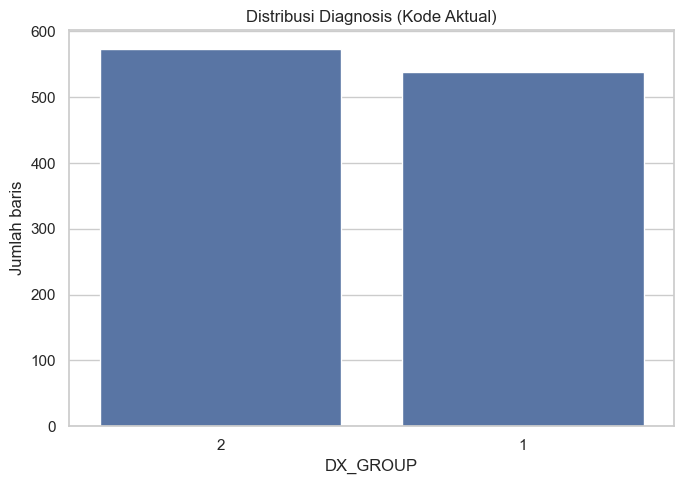

Interpretasi: gunakan kode aktual pada tabel dan verifikasi pemetaan ASD/TD melalui dokumentasi ABIDE I.


In [36]:
if "DX_GROUP" not in df_raw.columns:
    print("Kolom DX_GROUP tidak tersedia; analisis diagnosis dilewati.")
else:
    diagnosis_distribution = (
df_raw["DX_GROUP"].value_counts(dropna=False)
.rename_axis("DX_GROUP")
.reset_index(name="count")
    )
    diagnosis_distribution["percentage"] = diagnosis_distribution["count"] / len(df_raw) * 100
    display(diagnosis_distribution)
    display(diagnosis_distribution)
    
    plt.figure(figsize=(7, 5))
    sns.countplot(data=df_raw, x="DX_GROUP", order=diagnosis_distribution["DX_GROUP"])
    plt.title("Distribusi Diagnosis (Kode Aktual)")
    plt.xlabel("DX_GROUP")
    plt.ylabel("Jumlah baris")
    finish_figure()
    plt.show()
    print("Interpretasi: gunakan kode aktual pada tabel dan verifikasi pemetaan ASD/TD melalui dokumentasi ABIDE I.")

## 7. Usia saat pemindaian

Grafik menggunakan salinan `df_analysis`, sehingga nilai `-9999` tidak ikut membentuk histogram atau boxplot. Jika kolom diagnosis tersedia, perbandingan tetap ditampilkan berdasarkan kode aktual.

,count,mean,std,min,25%,50%,75%,max
AGE_AT_SCAN,1112.0,17.048864,8.036419,6.47,11.658575,14.66,20.085,64.0


,count,mean,std,min,25%,50%,75%,max
AGE_AT_SCAN,1112.0,17.048864,8.036419,6.47,11.658575,14.66,20.085,64.0


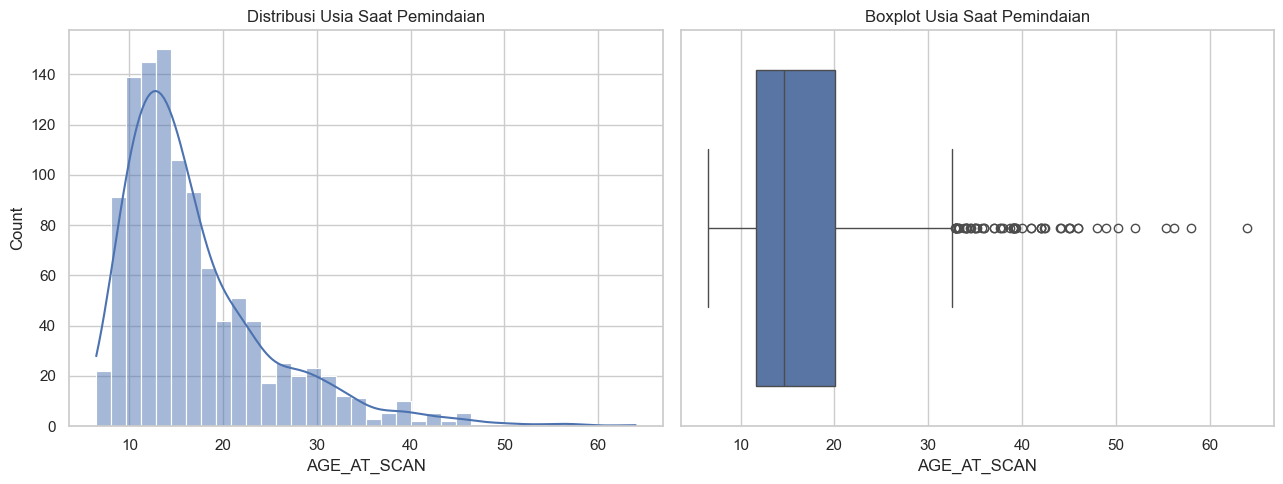

,count,mean,std,min,25%,50%,75%,max
DX_GROUP,,,,,,,,
1,539.0,17.013146,8.366424,7.00,11.53,14.42,19.67215,64.0
2,573.0,17.082463,7.720320,6.47,11.80,14.80,20.65000,56.2


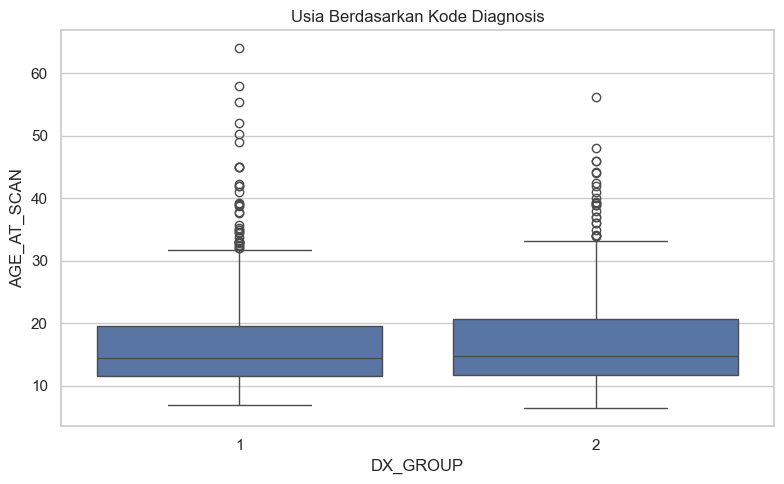

In [37]:
if "AGE_AT_SCAN" not in df_analysis.columns:
    print("Kolom AGE_AT_SCAN tidak tersedia; analisis usia dilewati.")
else:
    age = pd.to_numeric(df_analysis["AGE_AT_SCAN"], errors="coerce")
    age_summary = age.describe().to_frame().T
    display(age_summary)
    display(age_summary)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.histplot(age.dropna(), kde=True, ax=axes[0])
    axes[0].set_title("Distribusi Usia Saat Pemindaian")
    axes[0].set_xlabel("AGE_AT_SCAN")
    sns.boxplot(x=age.dropna(), ax=axes[1])
    axes[1].set_title("Boxplot Usia Saat Pemindaian")
    axes[1].set_xlabel("AGE_AT_SCAN")
    finish_figure()
    plt.show()

    if "DX_GROUP" in df_analysis.columns:
        age_by_diagnosis = pd.DataFrame({"DX_GROUP": df_analysis["DX_GROUP"], "AGE_AT_SCAN": age}).dropna(subset=["AGE_AT_SCAN"])
        display(age_by_diagnosis.groupby("DX_GROUP")["AGE_AT_SCAN"].describe())
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=age_by_diagnosis, x="DX_GROUP", y="AGE_AT_SCAN")
        plt.title("Usia Berdasarkan Kode Diagnosis")
        plt.xlabel("DX_GROUP")
        plt.ylabel("AGE_AT_SCAN")
        finish_figure()
        plt.show()

## 8. Jenis kelamin, FIQ, dan handedness

Setiap analisis dijalankan hanya jika kolom tersedia. FIQ ditampilkan sebagai data deskriptif; notebook tidak melakukan imputasi atau standardisasi.

,SEX,count,percentage
0,1,948,85.251799
1,2,164,14.748201


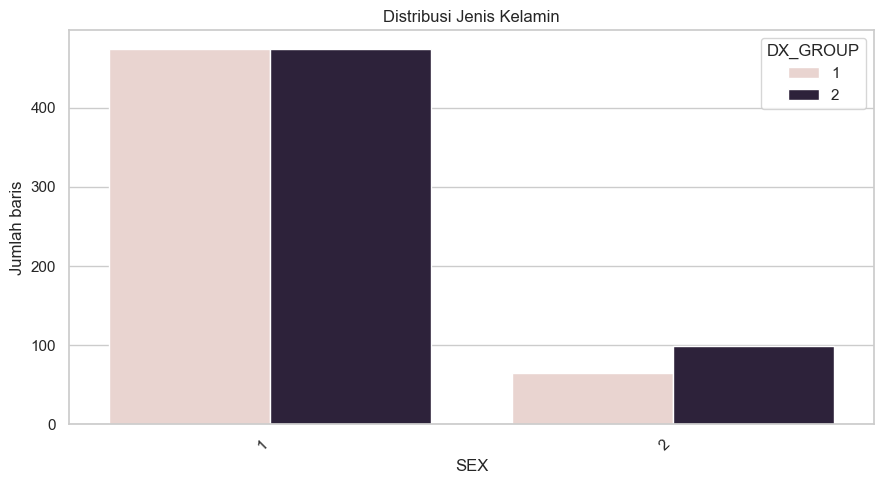

,HANDEDNESS_CATEGORY,count,percentage
0,R,693,62.320144
1,NaN,326,29.316547
2,L,71,6.384892
3,Ambi,15,1.348921
4,Mixed,6,0.539568
5,L->R,1,0.089928


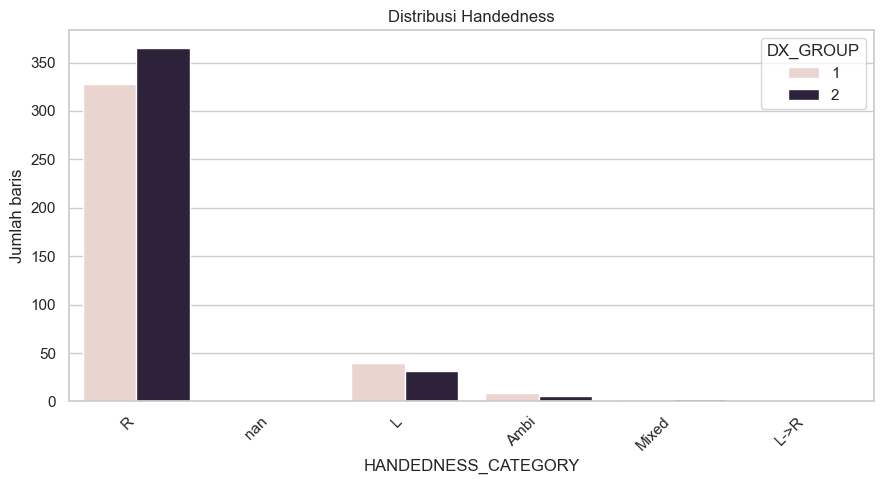

,HANDEDNESS_CATEGORY,count,percentage
0,R,693,62.320144
1,NaN,326,29.316547
2,L,71,6.384892
3,Ambi,15,1.348921
4,Mixed,6,0.539568
5,L->R,1,0.089928


In [39]:
def categorical_eda(frame, column, filename_prefix, title):
    if column not in frame.columns:
        print(f"Kolom {column} tidak tersedia; analisis dilewati.")
        return None
    values = frame[column].value_counts(dropna=False).rename_axis(column).reset_index(name="count")
    values["percentage"] = values["count"] / len(frame) * 100
    display(values)
    plt.figure(figsize=(9, 5))
    if "DX_GROUP" in frame.columns:
        plot_data = frame[[column, "DX_GROUP"]].copy()
        plot_data[column] = plot_data[column].fillna("NaN")
        sns.countplot(data=plot_data, x=column, hue="DX_GROUP", order=values[column].astype(str))
        plt.legend(title="DX_GROUP")
    else:
        plot_data = frame.copy()
        plot_data[column] = plot_data[column].fillna("NaN")
        sns.countplot(data=plot_data, x=column, order=values[column].astype(str))
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Jumlah baris")
    plt.xticks(rotation=45, ha="right")
    finish_figure()
    plt.show()
    return values

categorical_eda(df_analysis, "SEX", "jenis_kelamin", "Distribusi Jenis Kelamin")
categorical_eda(df_analysis, "HANDEDNESS_CATEGORY", "handedness", "Distribusi Handedness")

,count,mean,std,min,25%,50%,75%,max
FIQ,1040.0,108.380962,15.072062,41.0,99.0,109.0,119.0,148.0


,count,mean,std,min,25%,50%,75%,max
FIQ,1040.0,108.380962,15.072062,41.0,99.0,109.0,119.0,148.0


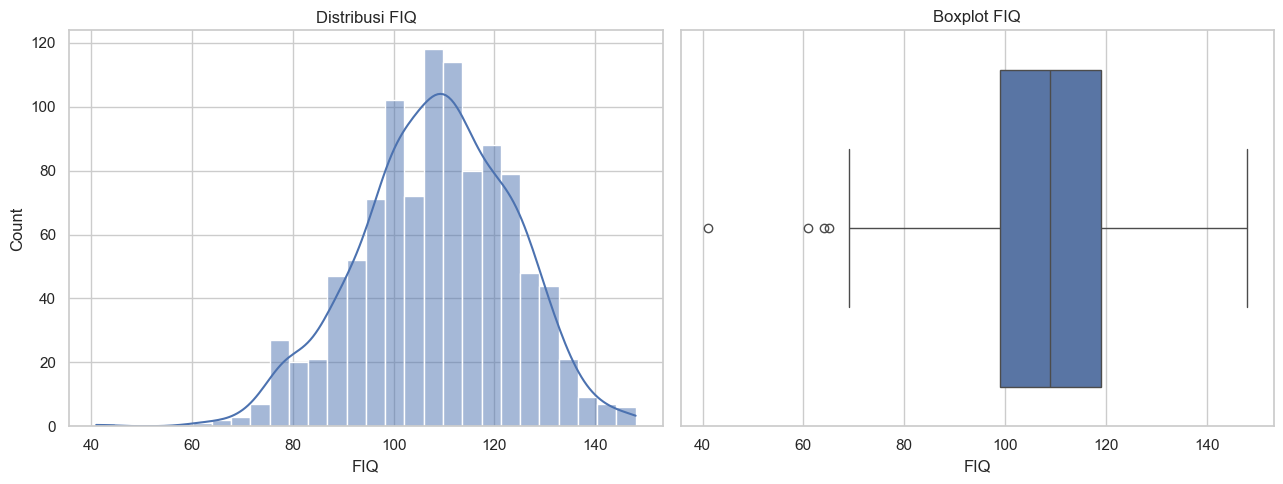

,count,mean,std,min,25%,50%,75%,max
DX_GROUP,,,,,,,,
1,505.0,105.345743,17.005317,41.0,94.0,105.0,118.0,148.0
2,535.0,111.245981,12.333965,73.0,103.5,111.0,120.0,148.0


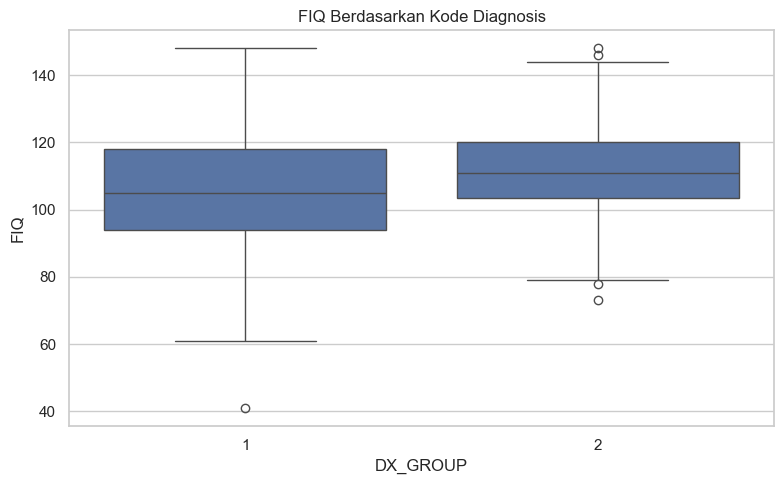

In [40]:
if "FIQ" not in df_analysis.columns:
    print("Kolom FIQ tidak tersedia; analisis FIQ dilewati.")
else:
    fiq = pd.to_numeric(df_analysis["FIQ"], errors="coerce")
    fiq_summary = fiq.describe().to_frame().T
    display(fiq_summary)
    display(fiq_summary)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.histplot(fiq.dropna(), kde=True, ax=axes[0])
    axes[0].set_title("Distribusi FIQ")
    axes[0].set_xlabel("FIQ")
    sns.boxplot(x=fiq.dropna(), ax=axes[1])
    axes[1].set_title("Boxplot FIQ")
    axes[1].set_xlabel("FIQ")
    finish_figure()
    plt.show()
    if "DX_GROUP" in df_analysis.columns:
        fiq_by_diagnosis = pd.DataFrame({"DX_GROUP": df_analysis["DX_GROUP"], "FIQ": fiq}).dropna(subset=["FIQ"])
        display(fiq_by_diagnosis.groupby("DX_GROUP")["FIQ"].describe())
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=fiq_by_diagnosis, x="DX_GROUP", y="FIQ")
        plt.title("FIQ Berdasarkan Kode Diagnosis")
        plt.xlabel("DX_GROUP")
        plt.ylabel("FIQ")
        finish_figure()
        plt.show()

## 9. Distribusi per situs

Tabel dan grafik berikut bersifat deskriptif. Perbedaan jumlah atau proporsi diagnosis antar-site tidak boleh langsung ditafsirkan sebagai efek biologis.

DX_GROUP,1,2,total,max_class_share_pct
SITE_ID,,,,
NYU,79,105,184,57.065217
UM_1,55,55,110,50.000000
USM,58,43,101,57.425743
UCLA_1,49,33,82,59.756098
PITT,30,27,57,52.631579
MAX_MUN,24,33,57,57.894737
YALE,28,28,56,50.000000
KKI,22,33,55,60.000000
TRINITY,24,25,49,51.020408


DX_GROUP,1,2,total,max_class_share_pct
SITE_ID,,,,
NYU,79,105,184,57.065217
UM_1,55,55,110,50.000000
USM,58,43,101,57.425743
UCLA_1,49,33,82,59.756098
PITT,30,27,57,52.631579
MAX_MUN,24,33,57,57.894737
YALE,28,28,56,50.000000
KKI,22,33,55,60.000000
TRINITY,24,25,49,51.020408


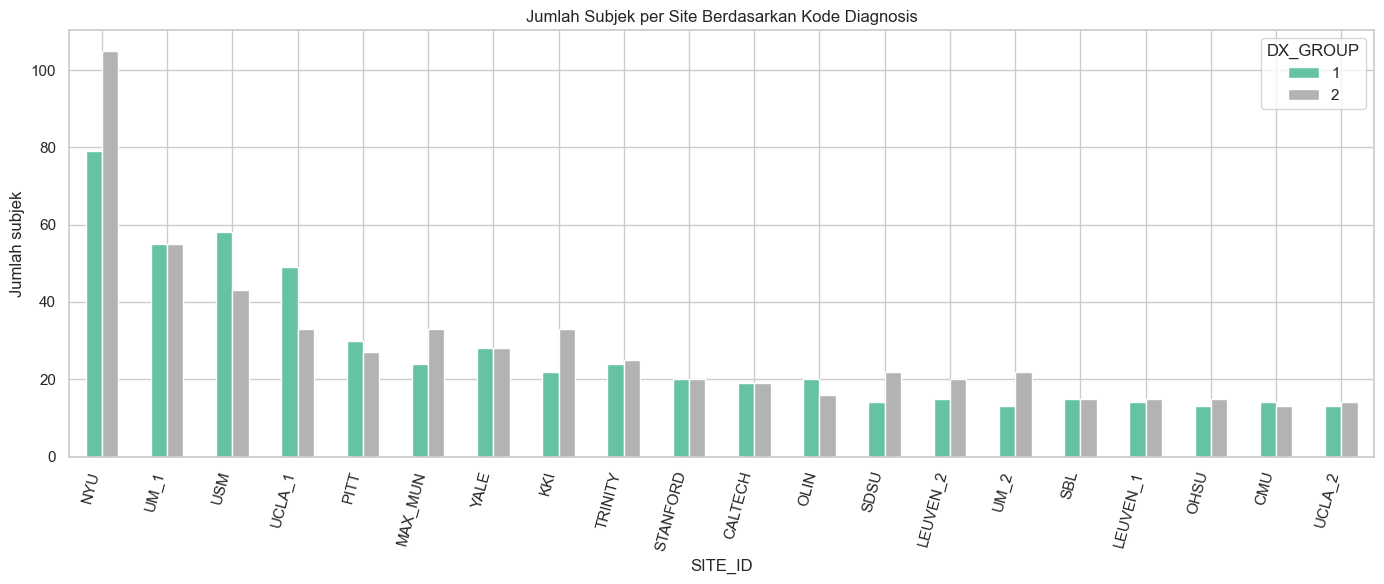

Site berjumlah sedikit dapat ditinjau dari tabel; batas 'sedikit' tidak ditetapkan otomatis.


In [41]:
if "SITE_ID" not in df_analysis.columns:
    print("Kolom SITE_ID tidak tersedia; analisis site dilewati.")
else:
    site_data = df_analysis[["SITE_ID"] + (["DX_GROUP"] if "DX_GROUP" in df_analysis.columns else [])].copy()
    site_data["SITE_ID"] = site_data["SITE_ID"].fillna("NaN")
    if "DX_GROUP" in site_data.columns:
        site_summary = pd.crosstab(site_data["SITE_ID"], site_data["DX_GROUP"], dropna=False)
        site_summary["total"] = site_summary.sum(axis=1)
        site_summary["max_class_share_pct"] = site_summary.drop(columns="total").div(site_summary["total"], axis=0).max(axis=1) * 100
        site_summary = site_summary.sort_values("total", ascending=False)
        display(site_summary)
        display(site_summary)
        plot_table = site_summary.sort_values("total", ascending=False).drop(columns=["total", "max_class_share_pct"], errors="ignore")
        plot_table.plot(kind="bar", stacked=False, figsize=(14, 6), colormap="Set2")
        plt.title("Jumlah Subjek per Site Berdasarkan Kode Diagnosis")
        plt.xlabel("SITE_ID")
        plt.ylabel("Jumlah subjek")
        plt.xticks(rotation=75, ha="right")
        plt.legend(title="DX_GROUP")
        finish_figure()
        plt.show()
        print("Site berjumlah sedikit dapat ditinjau dari tabel; batas 'sedikit' tidak ditetapkan otomatis.")
    else:
        site_summary = site_data["SITE_ID"].value_counts().rename_axis("SITE_ID").to_frame("total")
        display(site_summary)
        display(site_summary)
        site_summary.plot(kind="bar", figsize=(14, 6), legend=False)
        plt.title("Jumlah Subjek per Site")
        plt.xlabel("SITE_ID")
        plt.ylabel("Jumlah subjek")
        plt.xticks(rotation=75, ha="right")
        finish_figure()
        plt.show()

## 10. Ringkasan otomatis

Bagian ini memisahkan **observasi yang dihitung dari data** dan **interpretasi yang masih perlu diverifikasi**. Ringkasan tidak menyimpulkan kualitas data atau hubungan sebab-akibat.

In [42]:
print("=" * 70)
print("RINGKASAN EDA FENOTIPIK ABIDE I")
print("=" * 70)
print(f"Ukuran dataset: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"Duplikasi baris keseluruhan: {int(df_raw.duplicated().sum())}")
if "SUB_ID" in df_raw.columns:
    print(f"SUB_ID unik: {df_raw['SUB_ID'].nunique(dropna=True)}")
    print(f"Baris SUB_ID kosong: {int(df_raw['SUB_ID'].isna().sum())}")
    print(f"Baris dengan SUB_ID duplikat: {int(df_raw['SUB_ID'].duplicated(keep=False).sum())}")
print("\nObservasi missing konseptual terbanyak:")
print(missing_report.head(5)[["conceptual_missing_count", "conceptual_missing_pct"]].to_string())
if "DX_GROUP" in df_raw.columns:
    print("\nDistribusi diagnosis (kode aktual):")
    print(diagnosis_distribution.to_string(index=False))
else:
    print("\nDX_GROUP tidak tersedia, sehingga distribusi diagnosis tidak dapat dihitung.")
for column in ["AGE_AT_SCAN", "FIQ", "SEX", "HANDEDNESS_CATEGORY", "SITE_ID"]:
    if column in df_raw.columns:
        print(f"\n{column}: tersedia; lihat tabel dan grafik tersimpan untuk ringkasan deskriptif.")
    else:
        print(f"\n{column}: tidak tersedia pada CSV ini; analisis dilewati.")
print("\nInterpretasi dan keterbatasan:")
print("- Nilai khusus seperti -9999 belum dihapus atau diganti pada df_raw.")
print("- Arti nilai khusus harus diverifikasi dari dokumentasi ABIDE I per variabel.")
print("- EDA ini belum melakukan matching subject ID dengan file sMRI.")
print("- EDA ini belum melakukan cleaning, imputasi, split data, preprocessing, atau pemodelan.")
print("- Perbedaan antar-site hanya dilaporkan secara deskriptif dan bukan bukti efek biologis.")
print("- Pemeriksaan lanjutan diperlukan sebelum menetapkan aturan cleaning dan dataset modeling.")

RINGKASAN EDA FENOTIPIK ABIDE I
Ukuran dataset: 1112 baris x 75 kolom
Duplikasi baris keseluruhan: 0
SUB_ID unik: 1112
Baris SUB_ID kosong: 0
Baris dengan SUB_ID duplikat: 0

Observasi missing konseptual terbanyak:
                    conceptual_missing_count  conceptual_missing_pct
WISC_IV_VCI                             1057               95.053957
WISC_IV_PRI                             1057               95.053957
WISC_IV_WMI                             1057               95.053957
WISC_IV_PSI                             1057               95.053957
WISC_IV_SIM_SCALED                      1057               95.053957

Distribusi diagnosis (kode aktual):
 DX_GROUP  count  percentage
        2    573   51.528777
        1    539   48.471223

AGE_AT_SCAN: tersedia; lihat tabel dan grafik tersimpan untuk ringkasan deskriptif.

FIQ: tersedia; lihat tabel dan grafik tersimpan untuk ringkasan deskriptif.

SEX: tersedia; lihat tabel dan grafik tersimpan untuk ringkasan deskriptif.

HANDEDN